##Dataset Download

1.   List item
2.   List item



In [ ]:
!pip install -q kaggle mlflow

In [ ]:
import kagglehub

path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Path to dataset files: /kaggle/input/chest-xray-pneumonia


In [ ]:
import os
data_dir = "/kaggle/input/chest-xray-pneumonia/chest_xray"
print(os.listdir(data_dir))

['chest_xray', '__MACOSX', 'val', 'test', 'train']


##Exploration

In [ ]:
import os
for split in ["train", "val", "test"]:
    print(f"\n{split.upper()}")
    split_path = os.path.join(data_dir, split)

    for label in os.listdir(split_path):
        label_path = os.path.join(split_path, label)

        if os.path.isdir(label_path):
            images = [
                f for f in os.listdir(label_path)
                if f.lower().endswith((".jpg", ".jpeg", ".png"))]

            print(f"{label}: {len(images)} images")


TRAIN
PNEUMONIA: 3875 images
NORMAL: 1341 images

VAL
PNEUMONIA: 8 images
NORMAL: 8 images

TEST
PNEUMONIA: 390 images
NORMAL: 234 images


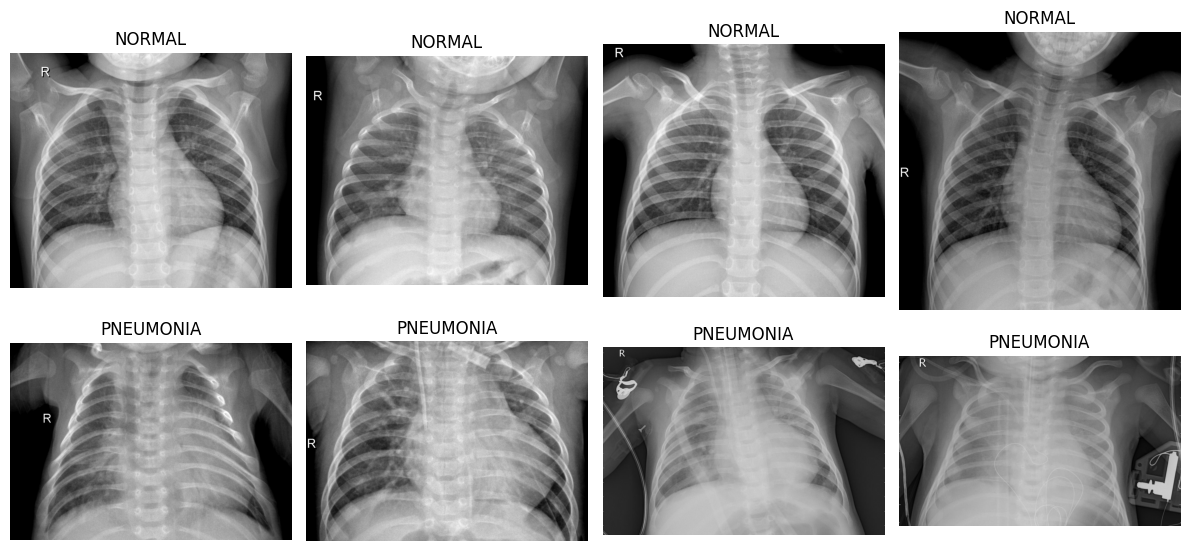

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import os
import random

train_path = os.path.join(data_dir, "train")

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for row, label in enumerate(["NORMAL", "PNEUMONIA"]):
    folder = os.path.join(train_path, label)

    files = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))]

    for col, file in enumerate(random.sample(files, 4)):
        img = Image.open(os.path.join(folder, file))

        axes[row, col].imshow(img, cmap="gray")
        axes[row, col].set_title(label)
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from PIL import Image
from collections import Counter
import os

sizes = Counter()
train_path = os.path.join(data_dir, "train")

for label in ["NORMAL", "PNEUMONIA"]:
    folder = os.path.join(train_path, label)

    for file in os.listdir(folder):
        path = os.path.join(folder, file)

        try:
            with Image.open(path) as img:
                sizes[img.size] += 1
        except Exception:
            pass

print("Most common image dimensions:")
for size, count in sizes.most_common(10):
    print(size, ":", count, "images")

Most common image dimensions:
(1072, 648) : 7 images
(1080, 728) : 6 images
(1008, 704) : 5 images
(1008, 680) : 5 images
(976, 672) : 5 images
(1216, 872) : 5 images
(992, 592) : 5 images
(1064, 760) : 5 images
(1304, 968) : 4 images
(1024, 632) : 4 images


In [ ]:
from PIL import Image
import os

bad_images = []
extensions = (".jpg", ".jpeg", ".png", ".bmp")

for split in ["train", "val", "test"]:
    split_path = os.path.join(data_dir, split)

    for label in ["NORMAL", "PNEUMONIA"]:
        folder = os.path.join(split_path, label)

        for file in os.listdir(folder):
            if file.lower().endswith(extensions):
                path = os.path.join(folder, file)

                try:
                    with Image.open(path) as img:
                        img.verify()
                except Exception:
                    bad_images.append(path)

print("Corrupted images:", len(bad_images))

Corrupted images: 0


##preprocessing

In [ ]:
import tensorflow as tf
import os

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(data_dir, "train"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    color_mode="rgb",
    shuffle=True,
    seed=42
)

print("Classes:", train_ds.class_names)

Found 5216 files belonging to 2 classes.
Classes: ['NORMAL', 'PNEUMONIA']


In [ ]:
normalization = tf.keras.layers.Rescaling(1./255)

train_ds = train_ds.map(lambda images, labels: (normalization(images), labels))

print("Normalization completed!")

Normalization completed!


In [ ]:
import os
import tensorflow as tf

CLASS_NAMES = ["NORMAL", "PNEUMONIA"]

val_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(data_dir, "val"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    color_mode="rgb",
    class_names=CLASS_NAMES,
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(data_dir, "test"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    color_mode="rgb",
    class_names=CLASS_NAMES,
    shuffle=False
)

val_ds = val_ds.map(
    lambda images, labels: (normalization(images), labels)
)

test_ds = test_ds.map(
    lambda images, labels: (normalization(images), labels)
)

print("Preprocessing completed!")

Found 16 files belonging to 2 classes.
Found 624 files belonging to 2 classes.
Preprocessing completed!


In [ ]:
import os

for split in ["train", "val", "test"]:
    print(f"\n{split.upper()}")

    for label in ["NORMAL", "PNEUMONIA"]:
        folder = os.path.join(data_dir, split, label)

        if os.path.isdir(folder):
            count = sum(
                1 for f in os.listdir(folder)
                if f.lower().endswith((".jpg", ".jpeg", ".png"))
            )
            print(f"{label}: {count}")


TRAIN
NORMAL: 1341
PNEUMONIA: 3875

VAL
NORMAL: 8
PNEUMONIA: 8

TEST
NORMAL: 234
PNEUMONIA: 390


In [ ]:
import os

for label in ["NORMAL", "PNEUMONIA"]:
    train_folder = os.path.join(data_dir, "train", label)
    val_folder = os.path.join(data_dir, "val", label)

    train_count = len([
        f for f in os.listdir(train_folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])

    val_count = len([
        f for f in os.listdir(val_folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])

    print(f"{label}: Train={train_count}, Validation={val_count}")

NORMAL: Train=1341, Validation=8
PNEUMONIA: Train=3875, Validation=8


In [ ]:
import os

for split in ["train", "val", "test"]:
    print(f"\n{split.upper()}")
    for label in ["NORMAL", "PNEUMONIA"]:
        folder = os.path.join(data_dir, split, label)
        count = sum(
            1 for f in os.listdir(folder)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        )
        print(f"{label}: {count} images")


TRAIN
NORMAL: 1341 images
PNEUMONIA: 3875 images

VAL
NORMAL: 8 images
PNEUMONIA: 8 images

TEST
NORMAL: 234 images
PNEUMONIA: 390 images


In [ ]:
import os

for split in ["train", "val", "test"]:
    print(f"\n{split.upper()}")
    for cls in ["NORMAL", "PNEUMONIA"]:
        folder = os.path.join(data_dir, split, cls)
        if os.path.exists(folder):
            count = len([
                f for f in os.listdir(folder)
                if f.lower().endswith((".jpg", ".jpeg", ".png"))
            ])
            print(f"{cls}: {count}")


TRAIN
NORMAL: 1341
PNEUMONIA: 3875

VAL
NORMAL: 8
PNEUMONIA: 8

TEST
NORMAL: 234
PNEUMONIA: 390


In [ ]:
import os

for split in ["train", "val", "test"]:
    for label in ["NORMAL", "PNEUMONIA"]:
        folder = os.path.join(data_dir, split, label)

        count = (
            len([
                f for f in os.listdir(folder)
                if f.lower().endswith((".jpg", ".jpeg", ".png"))
            ])
            if os.path.isdir(folder) else 0
        )

        print(f"{split}/{label}: {count}")

train/NORMAL: 1341
train/PNEUMONIA: 3875
val/NORMAL: 8
val/PNEUMONIA: 8
test/NORMAL: 234
test/PNEUMONIA: 390


In [ ]:
data_dir = "/content/chest_xray/chest_xray"

In [ ]:
import os
import shutil
from sklearn.model_selection import train_test_split

data_dir = "/kaggle/input/chest-xray-pneumonia/chest_xray"
source_dir = os.path.join(data_dir, "train")
output_dir = "/content/chest_xray_split"

shutil.rmtree(output_dir, ignore_errors=True)   

image_paths = []
labels = []

for label in ["NORMAL", "PNEUMONIA"]:
    folder = os.path.join(source_dir, label)

    for filename in os.listdir(folder):
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            image_paths.append(os.path.join(folder, filename))
            labels.append(label)

X_train, X_val, y_train, y_val = train_test_split(
    image_paths,
    labels,
    test_size=0.20,
    stratify=labels,
    random_state=42
)


for split in ["train", "val"]:
    for label in ["NORMAL", "PNEUMONIA"]:
        os.makedirs(
            os.path.join(output_dir, split, label),
            exist_ok=True
        )


for paths, split_labels, split in [
    (X_train, y_train, "train"),
    (X_val, y_val, "val")
]:
    for src, label in zip(paths, split_labels):
        dst = os.path.join(
            output_dir, split, label, os.path.basename(src)
        )
        shutil.copy2(src, dst)

print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Random state: 42")

Training: 4172
Validation: 1044
Random state: 42


In [ ]:
import numpy as np

print("Unique labels:", np.unique(y_train))
print("Label dtype:", np.asarray(y_train).dtype)
print("Label counts:", np.unique(y_train, return_counts=True))

Unique labels: ['NORMAL' 'PNEUMONIA']
Label dtype: <U9
Label counts: (array(['NORMAL', 'PNEUMONIA'], dtype='<U9'), array([1073, 3099]))


In [ ]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

classes = np.array(["NORMAL", "PNEUMONIA"])

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    0: class_weights_array[0],  # NORMAL
    1: class_weights_array[1]   # PNEUMONIA
}

print("Class weights:", class_weights)

Class weights: {0: np.float64(1.9440820130475303), 1: np.float64(0.6731203614069055)}


In [ ]:

split_dir = "/content/chest_xray_split"
CLASS_NAMES = ["NORMAL", "PNEUMONIA"]

train_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(split_dir, "train"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    color_mode="rgb",
    class_names=CLASS_NAMES,
    shuffle=True,
    seed=42
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(split_dir, "val"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    color_mode="rgb",
    class_names=CLASS_NAMES,
    shuffle=False
)

normalization = tf.keras.layers.Rescaling(1./255)

train_ds = train_ds.map(lambda x, y: (normalization(x), y)).prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.map(lambda x, y: (normalization(x), y)).prefetch(tf.data.AUTOTUNE)

print("Datasets ready from:", split_dir)

Found 4172 files belonging to 2 classes.
Found 1044 files belonging to 2 classes.
Datasets ready from: /content/chest_xray_split


##CNN Model Building

### MLflow setup

In [ ]:
import numpy as np
import mlflow
import mlflow.keras
from sklearn.metrics import roc_curve


tf.keras.utils.set_random_seed(42)

EXPERIMENT = "pneumonia-xray-classification"

mlflow.set_tracking_uri("sqlite:///mlflow.db")   
mlflow.set_experiment(EXPERIMENT)


USE_CLASS_WEIGHT = True
FIT_CLASS_WEIGHT = class_weights if USE_CLASS_WEIGHT else None


class MlflowEpochLogger(tf.keras.callbacks.Callback):
    """Logs every Keras metric (loss, val_loss, accuracy, ...) to MLflow after each epoch."""
    def on_epoch_end(self, epoch, logs=None):
        mlflow.log_metrics({k: float(v) for k, v in (logs or {}).items()}, step=epoch)


def log_keras_model(model, name="model"):

    try:
        mlflow.keras.log_model(model, name=name)
    except TypeError:
        mlflow.keras.log_model(model, artifact_path=name)

CNN_EPOCHS = 15   


def labels_of(ds):
    return np.concatenate([l.numpy().reshape(-1) for _, l in ds]).astype(int)


def pick_threshold(y_true, y_prob):
    """Choose the decision threshold on the VALIDATION set (maximises TPR - FPR)."""
    fpr, tpr, thr = roc_curve(y_true, y_prob)
    return min(float(thr[np.argmax(tpr - fpr)]), 1.0)

2026/10/28 02:14:45 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/28 02:14:45 INFO mlflow.store.db.utils: Updating database tables
2026/10/28 02:14:48 INFO mlflow.tracking.fluent: Experiment with name 'pneumonia-xray-classification' does not exist. Creating a new experiment.


In [ ]:
import tensorflow.keras
from tensorflow.keras import layers, models, optimizers, regularizers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization, GlobalAveragePooling2D, Input


In [ ]:
data_augmentation = models.Sequential([
    layers.RandomRotation(0.03),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(0.05, 0.05),
])

cnn = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    data_augmentation,

    layers.Conv2D(32, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),

    layers.Dense(
        64,
        activation="relu",
        kernel_regularizer=regularizers.l2(1e-4)
    ),
    layers.Dropout(0.4),

    layers.Dense(1, activation="sigmoid")
])

cnn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 102,241 (399.38 KB)

 Trainable params: 101,793 (397.63 KB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
import os

test_dir = os.path.join(data_dir, "test")

test_paths = []
test_labels = []

for label in ["NORMAL", "PNEUMONIA"]:
    folder = os.path.join(test_dir, label)

    for filename in os.listdir(folder):
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            test_paths.append(os.path.join(folder, filename))
            test_labels.append(label)

print("Total test images:", len(test_paths))
print("NORMAL:", test_labels.count("NORMAL"))
print("PNEUMONIA:", test_labels.count("PNEUMONIA"))

Total test images: 624
NORMAL: 234
PNEUMONIA: 390


In [ ]:

def load_image(path, label):
    image = tf.io.read_file(path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image = tf.image.resize(image, (224, 224))
    image = tf.cast(image, tf.float32) / 255.0

    image = tf.ensure_shape(image, (224, 224, 3))

    label = tf.cast(label == "PNEUMONIA", tf.float32)
    label = tf.ensure_shape(label, ())

    return image, label

test_ds = tf.data.Dataset.from_tensor_slices(
    (test_paths, test_labels)
)

test_ds = test_ds.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.batch(32).prefetch(tf.data.AUTOTUNE)

In [ ]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "best_pneumonia_cnn.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    MlflowEpochLogger()
]

with mlflow.start_run(run_name="cnn_baseline") as run:
    mlflow.set_tags({"stage": "experiment", "model_family": "custom_cnn"})
    mlflow.log_params({
        "img_size": 224, "batch_size": BATCH_SIZE, "epochs": CNN_EPOCHS,
        "optimizer": "adam", "learning_rate": 1e-3,
        "dropout": 0.4, "l2": 1e-4, "seed": 42,
        "use_class_weight": USE_CLASS_WEIGHT,
    })

    history = cnn.fit(
        train_ds,
        validation_data=val_ds,
        epochs=CNN_EPOCHS,
        class_weight=FIT_CLASS_WEIGHT,
        callbacks=callbacks
    )

    log_keras_model(cnn)
    cnn_run_id = run.info.run_id

print("CNN run id:", cnn_run_id)

Epoch 1/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 177ms/step - accuracy: 0.7461 - auc: 0.8537 - loss: 0.4725 - precision: 0.9298 - recall: 0.6951
Epoch 1: val_loss improved from None to 1.58205, saving model to best_pneumonia_cnn.keras

Epoch 1: finished saving model to best_pneumonia_cnn.keras
131/131 ━━━━━━━━━━━━━━━━━━━━ 41s 226ms/step - accuracy: 0.8171 - auc: 0.9062 - loss: 0.3901 - precision: 0.9541 - recall: 0.7919 - val_accuracy: 0.7433 - val_auc: 0.4448 - val_loss: 1.5821 - val_precision: 0.7433 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 2/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 179ms/step - accuracy: 0.8678 - auc: 0.9376 - loss: 0.3065 - precision: 0.9779 - recall: 0.8392
Epoch 2: val_loss did not improve from 1.58205
131/131 ━━━━━━━━━━━━━━━━━━━━ 32s 246ms/step - accuracy: 0.8756 - auc: 0.9407 - loss: 0.2990 - precision: 0.9725 - recall: 0.8567 - val_accuracy: 0.7433 - val_auc: 0.4736 - val_loss: 2.3918 - val_precision: 0.7433 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 3/1

2026/10/28 02:20:02 WARNING mlflow.keras.save: You are saving a Keras model without specifying model signature.


CNN run id: 9dd00b4f0a5b4c039a3d541d31ddb312


In [ ]:

val_res = cnn.evaluate(val_ds, return_dict=True, verbose=0)
print("VAL:", {k: round(float(v), 4) for k, v in val_res.items()})

p_test = cnn.predict(test_ds, verbose=0).ravel()
y_test_diag = labels_of(test_ds)
print("mean prob on NORMAL    :", p_test[y_test_diag == 0].mean().round(3))
print("mean prob on PNEUMONIA :", p_test[y_test_diag == 1].mean().round(3))
print("share predicted PNEUMONIA @0.5:", (p_test >= 0.5).mean().round(3))

VAL: {'accuracy': 0.863, 'auc': 0.962, 'loss': 0.2862, 'precision': 0.856, 'recall': 0.9807}
mean prob on NORMAL    : 0.807
mean prob on PNEUMONIA : 0.968
share predicted PNEUMONIA @0.5: 0.955


In [ ]:
print("Model Input Shape:", cnn.input_shape)
print("Test Dataset:", test_ds.element_spec)

Model Input Shape: (None, 224, 224, 3)
Test Dataset: (TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.float32, name=None))


In [ ]:
import tensorflow as tf

def fix_shape(images, labels):

    images = tf.ensure_shape(
        images, [None, 224, 224, 3]
    )

    labels = tf.ensure_shape(
        labels, [None]
    )

    return images, labels


fixed_test_ds = test_ds.map(
    fix_shape,
    num_parallel_calls=tf.data.AUTOTUNE
)

print("Fixed Shape:", fixed_test_ds.element_spec)

Fixed Shape: (TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.float32, name=None))


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
    log_loss
)


y_true = np.concatenate([
    labels.numpy().reshape(-1)
    for _, labels in test_ds
]).astype(int)

y_prob = cnn.predict(test_ds, verbose=0).reshape(-1)



y_val_true_cnn = labels_of(val_ds)
y_val_prob_cnn = cnn.predict(val_ds, verbose=0).reshape(-1)
CNN_THR = pick_threshold(y_val_true_cnn, y_val_prob_cnn)
print('CNN threshold (from validation):', round(CNN_THR, 3))

y_pred = (y_prob >= CNN_THR).astype(int)


test_loss = log_loss(y_true, np.clip(y_prob, 1e-7, 1 - 1e-7))
test_accuracy = accuracy_score(y_true, y_pred)
test_precision = precision_score(y_true, y_pred, zero_division=0)
test_recall = recall_score(y_true, y_pred, zero_division=0)
test_auc = roc_auc_score(y_true, y_prob)


print(f"Test Loss:      {test_loss:.4f}")
print(f"Test Accuracy:  {test_accuracy:.4f}")
print(f"Test Precision: {test_precision:.4f}")
print(f"Test Recall:    {test_recall:.4f}")
print(f"Test AUC:       {test_auc:.4f}")

CNN threshold (from validation): 0.904
Test Loss:      0.8916
Test Accuracy:  0.7965
Test Precision: 0.7816
Test Recall:    0.9359
Test AUC:       0.8856


In [ ]:
test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(data_dir, "test"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    color_mode="rgb",
    class_names=["NORMAL", "PNEUMONIA"],
    shuffle=False
)

test_ds = test_ds.map(
    lambda images, labels: (normalization(images), labels)
)

print("Test dataset ready!")

Found 624 files belonging to 2 classes.
Test dataset ready!


In [ ]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

y_true = np.concatenate([
    labels.numpy().reshape(-1)
    for _, labels in test_ds
]).astype(int)

y_prob = cnn.predict(test_ds)
y_pred = (y_prob.ravel() >= 0.5).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=["NORMAL", "PNEUMONIA"],
    digits=4
))

20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 144ms/step
Confusion Matrix:
[[ 23 211]
 [  5 385]]

Classification Report:
              precision    recall  f1-score   support

      NORMAL     0.8214    0.0983    0.1756       234
   PNEUMONIA     0.6460    0.9872    0.7809       390

    accuracy                         0.6538       624
   macro avg     0.7337    0.5427    0.4783       624
weighted avg     0.7118    0.6538    0.5539       624



In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix

y_val_true = np.concatenate([
    labels.numpy().reshape(-1)
    for _, labels in val_ds
]).astype(int)

y_val_prob = cnn.predict(val_ds, verbose=0).ravel()

for threshold in [0.3, 0.4, 0.5, 0.6, 0.7]:
    y_val_pred = (y_val_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val_true, y_val_pred, labels=[0, 1]
    ).ravel()

    normal_recall = tn / (tn + fp)
    pneumonia_recall = tp / (tp + fn)

    print(
        f"Threshold: {threshold:.1f} | "
        f"NORMAL Recall: {normal_recall:.3f} | "
        f"PNEUMONIA Recall: {pneumonia_recall:.3f}"
    )

Threshold: 0.3 | NORMAL Recall: 0.284 | PNEUMONIA Recall: 0.995
Threshold: 0.4 | NORMAL Recall: 0.392 | PNEUMONIA Recall: 0.987
Threshold: 0.5 | NORMAL Recall: 0.522 | PNEUMONIA Recall: 0.981
Threshold: 0.6 | NORMAL Recall: 0.619 | PNEUMONIA Recall: 0.973
Threshold: 0.7 | NORMAL Recall: 0.728 | PNEUMONIA Recall: 0.961


In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

y_test_true = np.concatenate([
    labels.numpy().reshape(-1)
    for _, labels in test_ds
]).astype(int)

y_test_prob = cnn.predict(test_ds, verbose=0).ravel()

threshold = 0.4
y_test_pred = (y_test_prob >= threshold).astype(int)

print("Threshold:", threshold)
print("Confusion Matrix:")
print(confusion_matrix(y_test_true, y_test_pred))

print("\nClassification Report:")
print(classification_report(
    y_test_true,
    y_test_pred,
    target_names=["NORMAL", "PNEUMONIA"],
    digits=4
))

Threshold: 0.4
Confusion Matrix:
[[ 16 218]
 [  4 386]]

Classification Report:
              precision    recall  f1-score   support

      NORMAL     0.8000    0.0684    0.1260       234
   PNEUMONIA     0.6391    0.9897    0.7767       390

    accuracy                         0.6442       624
   macro avg     0.7195    0.5291    0.4513       624
weighted avg     0.6994    0.6442    0.5327       624



In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

y_val_true = np.concatenate([
    labels.numpy().reshape(-1)
    for _, labels in val_ds
]).astype(int)

y_val_prob = cnn.predict(val_ds, verbose=0).ravel()

for threshold in [0.3, 0.4, 0.5, 0.6, 0.7]:
    y_val_pred = (y_val_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val_true, y_val_pred, labels=[0, 1]
    ).ravel()

    normal_recall = tn / (tn + fp)
    pneumonia_recall = tp / (tp + fn)

    print(
        f"Threshold={threshold:.1f} | "
        f"NORMAL recall={normal_recall:.3f} | "
        f"PNEUMONIA recall={pneumonia_recall:.3f}"
    )

Threshold=0.3 | NORMAL recall=0.284 | PNEUMONIA recall=0.995
Threshold=0.4 | NORMAL recall=0.392 | PNEUMONIA recall=0.987
Threshold=0.5 | NORMAL recall=0.522 | PNEUMONIA recall=0.981
Threshold=0.6 | NORMAL recall=0.619 | PNEUMONIA recall=0.973
Threshold=0.7 | NORMAL recall=0.728 | PNEUMONIA recall=0.961


In [ ]:
threshold = 0.4

y_val_pred = (y_val_prob >= threshold).astype(int)

from sklearn.metrics import classification_report, confusion_matrix

print(confusion_matrix(y_val_true, y_val_pred))

print(classification_report(
    y_val_true,
    y_val_pred,
    target_names=["NORMAL", "PNEUMONIA"],
    digits=4
))

[[105 163]
 [ 10 766]]
              precision    recall  f1-score   support

      NORMAL     0.9130    0.3918    0.5483       268
   PNEUMONIA     0.8245    0.9871    0.8985       776

    accuracy                         0.8343      1044
   macro avg     0.8688    0.6895    0.7234      1044
weighted avg     0.8473    0.8343    0.8086      1044



In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

y_test_true = np.concatenate([
    labels.numpy().reshape(-1)
    for _, labels in test_ds
]).astype(int)

y_test_prob = cnn.predict(test_ds, verbose=0).ravel()

threshold = 0.4
y_test_pred = (y_test_prob >= threshold).astype(int)

print("Test Confusion Matrix:")
print(confusion_matrix(y_test_true, y_test_pred))

print("\nTest Classification Report:")
print(classification_report(
    y_test_true,
    y_test_pred,
    target_names=["NORMAL", "PNEUMONIA"],
    digits=4
))

Test Confusion Matrix:
[[ 16 218]
 [  4 386]]

Test Classification Report:
              precision    recall  f1-score   support

      NORMAL     0.8000    0.0684    0.1260       234
   PNEUMONIA     0.6391    0.9897    0.7767       390

    accuracy                         0.6442       624
   macro avg     0.7195    0.5291    0.4513       624
weighted avg     0.6994    0.6442    0.5327       624



In [ ]:
for name, ds in [("Train", train_ds), ("Validation", val_ds)]:
    images, labels = next(iter(ds))

    print(
        name,
        "| Min:", float(tf.reduce_min(images)),
        "| Max:", float(tf.reduce_max(images)),
        "| Mean:", float(tf.reduce_mean(images))
    )

Train | Min: 0.0 | Max: 1.0 | Mean: 0.4818827211856842
Validation | Min: 0.0 | Max: 1.0 | Mean: 0.46251845359802246


In [ ]:
import numpy as np

pred1 = cnn.predict(val_ds, verbose=0).ravel()
pred2 = cnn.predict(val_ds, verbose=0).ravel()

print("Predictions consistent:", np.allclose(pred1, pred2, atol=1e-6))
print("Maximum difference:", np.max(np.abs(pred1 - pred2)))

Predictions consistent: True
Maximum difference: 0.0


In [ ]:
val_results = cnn.evaluate(val_ds, return_dict=True)

print("Current Validation Loss:", val_results["loss"])
print("Current Validation Accuracy:", val_results["accuracy"])

33/33 ━━━━━━━━━━━━━━━━━━━━ 6s 165ms/step - accuracy: 0.8630 - auc: 0.9620 - loss: 0.2862 - precision: 0.8560 - recall: 0.9807
Current Validation Loss: 0.28620874881744385
Current Validation Accuracy: 0.8630267977714539


In [ ]:
print("Train batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy())

Train batches: 131
Validation batches: 33
Test batches: 20


## ResNet

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers


def prepare_for_resnet(images, labels):
    images = images * 255.0
    images = tf.keras.applications.resnet50.preprocess_input(images)
    return images, labels

train_ds_resnet = train_ds.map(
    prepare_for_resnet,
    num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)

val_ds_resnet = val_ds.map(
    prepare_for_resnet,
    num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)

test_ds_resnet = test_ds.map(
    prepare_for_resnet,
    num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)

In [ ]:
base_model = tf.keras.applications.ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3))

x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

x = layers.Dense(
    128,
    activation="relu",
    kernel_regularizer=regularizers.l2(1e-4)
)(x)

x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

resnet_model = models.Model(inputs, outputs)

resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

resnet_model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,850,113 (90.98 MB)

 Trainable params: 262,401 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [ ]:
resnet_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "best_resnet50.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    MlflowEpochLogger()
]

with mlflow.start_run(run_name="resnet50_frozen") as run:
    mlflow.set_tags({"stage": "experiment", "model_family": "resnet50"})
    mlflow.log_params({
        "img_size": 224, "batch_size": BATCH_SIZE, "epochs": 10,
        "optimizer": "adam", "learning_rate": 1e-3,
        "base_trainable": False, "dropout": 0.3, "dense_units": 128, "l2": 1e-4,
        "use_class_weight": USE_CLASS_WEIGHT,
    })

    history_resnet = resnet_model.fit(
        train_ds_resnet,
        validation_data=val_ds_resnet,
        epochs=10,
        class_weight=FIT_CLASS_WEIGHT,
        callbacks=resnet_callbacks
    )

    log_keras_model(resnet_model)
    resnet_run_id = run.info.run_id

print("ResNet run id:", resnet_run_id)

Epoch 1/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 238ms/step - accuracy: 0.8312 - auc: 0.9024 - loss: 0.4880 - precision: 0.9349 - recall: 0.8250
Epoch 1: val_loss improved from None to 0.17016, saving model to best_resnet50.keras

Epoch 1: finished saving model to best_resnet50.keras
131/131 ━━━━━━━━━━━━━━━━━━━━ 64s 362ms/step - accuracy: 0.9032 - auc: 0.9653 - loss: 0.2721 - precision: 0.9664 - recall: 0.9009 - val_accuracy: 0.9454 - val_auc: 0.9941 - val_loss: 0.1702 - val_precision: 0.9945 - val_recall: 0.9317 - learning_rate: 0.0010
Epoch 2/10
130/131 ━━━━━━━━━━━━━━━━━━━━ 0s 211ms/step - accuracy: 0.9433 - auc: 0.9903 - loss: 0.1452 - precision: 0.9821 - recall: 0.9400
Epoch 2: val_loss improved from 0.17016 to 0.10701, saving model to best_resnet50.keras

Epoch 2: finished saving model to best_resnet50.keras
131/131 ━━━━━━━━━━━━━━━━━━━━ 36s 275ms/step - accuracy: 0.9480 - auc: 0.9906 - loss: 0.1418 - precision: 0.9842 - recall: 0.9451 - val_accuracy: 0.9693 - val_auc: 0.9960 - val_loss:

2026/10/28 02:27:51 WARNING mlflow.keras.save: You are saving a Keras model without specifying model signature.


ResNet run id: 6b3f147707e6427b87c12e667ebf8174


In [ ]:
results_resnet = resnet_model.evaluate(
    test_ds_resnet,
    return_dict=True
)

print(results_resnet)

20/20 ━━━━━━━━━━━━━━━━━━━━ 7s 350ms/step - accuracy: 0.8221 - auc: 0.9411 - loss: 0.6408 - precision: 0.7818 - recall: 0.9923
{'accuracy': 0.8221153616905212, 'auc': 0.9411242604255676, 'loss': 0.6407995820045471, 'precision': 0.7818182110786438, 'recall': 0.9923076629638672}


In [ ]:


y_true = np.concatenate([
    labels.numpy().ravel()
    for _, labels in test_ds_resnet
])

y_prob = resnet_model.predict(test_ds_resnet).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=["NORMAL", "PNEUMONIA"],
    digits=4
))

20/20 ━━━━━━━━━━━━━━━━━━━━ 11s 310ms/step
Confusion Matrix:
[[126 108]
 [  3 387]]

Classification Report:
              precision    recall  f1-score   support

      NORMAL     0.9767    0.5385    0.6942       234
   PNEUMONIA     0.7818    0.9923    0.8746       390

    accuracy                         0.8221       624
   macro avg     0.8793    0.7654    0.7844       624
weighted avg     0.8549    0.8221    0.8069       624



In [ ]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix


y_val_true = np.concatenate([
    labels.numpy().ravel()
    for _, labels in val_ds_resnet
])

y_val_prob = resnet_model.predict(val_ds_resnet).ravel()

for threshold in [0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    y_val_pred = (y_val_prob >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print(confusion_matrix(y_val_true, y_val_pred))
    print(classification_report(
        y_val_true,
        y_val_pred,
        target_names=["NORMAL", "PNEUMONIA"],
        digits=3,
        zero_division=0
    ))

33/33 ━━━━━━━━━━━━━━━━━━━━ 10s 283ms/step

Threshold: 0.4
[[254  14]
 [ 16 760]]
              precision    recall  f1-score   support

      NORMAL      0.941     0.948     0.944       268
   PNEUMONIA      0.982     0.979     0.981       776

    accuracy                          0.971      1044
   macro avg      0.961     0.964     0.962      1044
weighted avg      0.971     0.971     0.971      1044


Threshold: 0.5
[[259   9]
 [ 18 758]]
              precision    recall  f1-score   support

      NORMAL      0.935     0.966     0.950       268
   PNEUMONIA      0.988     0.977     0.983       776

    accuracy                          0.974      1044
   macro avg      0.962     0.972     0.966      1044
weighted avg      0.975     0.974     0.974      1044


Threshold: 0.6
[[263   5]
 [ 20 756]]
              precision    recall  f1-score   support

      NORMAL      0.929     0.981     0.955       268
   PNEUMONIA      0.993     0.974     0.984       776

    accuracy           

In [ ]:
RESNET_THR = pick_threshold(y_val_true, y_val_prob)   
print("ResNet threshold (from validation):", round(RESNET_THR, 3))

ResNet threshold (from validation): 0.777


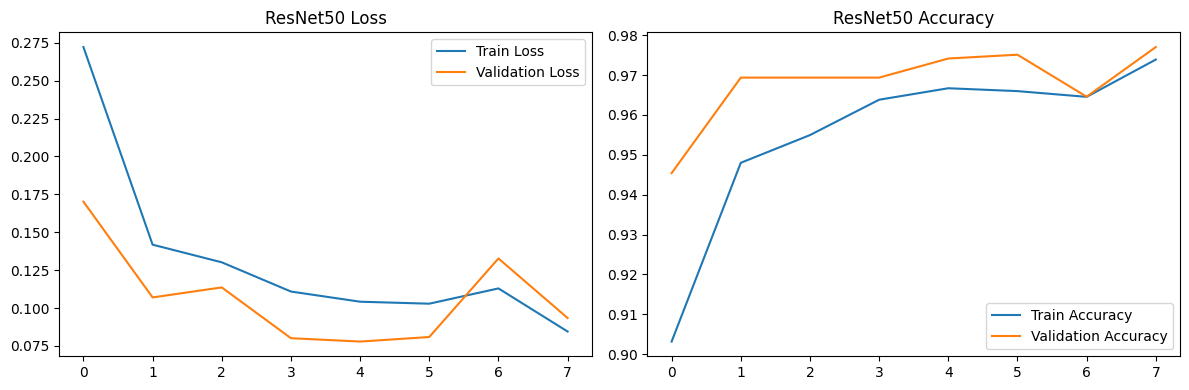

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_resnet.history["loss"], label="Train Loss")
plt.plot(history_resnet.history["val_loss"], label="Validation Loss")
plt.title("ResNet50 Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_resnet.history["accuracy"], label="Train Accuracy")
plt.plot(history_resnet.history["val_accuracy"], label="Validation Accuracy")
plt.title("ResNet50 Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

##densenet

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers

def prepare_for_densenet(images, labels):
    images = images * 255.0
    images = tf.keras.applications.densenet.preprocess_input(images)
    return images, labels

train_ds_dense = train_ds.map(
    prepare_for_densenet,
    num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)

val_ds_dense = val_ds.map(
    prepare_for_densenet,
    num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)

test_ds_dense = test_ds.map(
    prepare_for_densenet,
    num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)

print("DenseNet preprocessing completed!")

DenseNet preprocessing completed!


In [ ]:
base_model = tf.keras.applications.DenseNet121(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)
base_model.trainable = False

densenet_model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(
        1,
        activation="sigmoid",
        kernel_regularizer=regularizers.l2(0.001)
    )
])

densenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

densenet_model.summary()

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │         1,025 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,038,529 (26.85 MB)

 Trainable params: 1,025 (4.00 KB)

 Non-trainable params: 7,037,504 (26.85 MB)

In [ ]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

with mlflow.start_run(run_name="densenet121_frozen") as run:
    mlflow.set_tags({"stage": "experiment", "model_family": "densenet121"})
    mlflow.log_params({
        "img_size": 224, "batch_size": BATCH_SIZE, "epochs": 10,
        "optimizer": "adam", "learning_rate": 1e-4,
        "base_trainable": False, "dropout": 0.3, "l2": 1e-3,
        "use_class_weight": USE_CLASS_WEIGHT,
    })

    history_densenet = densenet_model.fit(
        train_ds_dense,
        validation_data=val_ds_dense,
        epochs=10,
        class_weight=FIT_CLASS_WEIGHT,
        callbacks=[early_stop, MlflowEpochLogger()]
    )

    log_keras_model(densenet_model)
    dense_run_id = run.info.run_id

print("DenseNet run id:", dense_run_id)

Epoch 1/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 98s 532ms/step - accuracy: 0.5892 - auc: 0.6116 - loss: 0.7272 - precision: 0.7946 - recall: 0.6028 - val_accuracy: 0.7433 - val_auc: 0.8451 - val_loss: 0.5735 - val_precision: 0.9291 - val_recall: 0.7088
Epoch 2/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 35s 266ms/step - accuracy: 0.6743 - auc: 0.7423 - loss: 0.6023 - precision: 0.8607 - recall: 0.6699 - val_accuracy: 0.8218 - val_auc: 0.9347 - val_loss: 0.4796 - val_precision: 0.9697 - val_recall: 0.7848
Epoch 3/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 35s 265ms/step - accuracy: 0.7359 - auc: 0.8277 - loss: 0.5139 - precision: 0.8958 - recall: 0.7293 - val_accuracy: 0.8736 - val_auc: 0.9584 - val_loss: 0.3969 - val_precision: 0.9721 - val_recall: 0.8544
Epoch 4/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 35s 267ms/step - accuracy: 0.7919 - auc: 0.8843 - loss: 0.4374 - precision: 0.9250 - recall: 0.7835 - val_accuracy: 0.8908 - val_auc: 0.9675 - val_loss: 0.3523 - val_precision: 0.9769 - val_recall: 0.8737
Epoch 5/10
131/131 ━

2026/10/28 02:36:08 WARNING mlflow.keras.save: You are saving a Keras model without specifying model signature.


DenseNet run id: 9bf66f0a175f45f29af330b1e4269110


In [ ]:
test_results = densenet_model.evaluate(
    test_ds_dense,
    return_dict=True
)

print("DenseNet Test Results:")
print(test_results)

20/20 ━━━━━━━━━━━━━━━━━━━━ 15s 771ms/step - accuracy: 0.8814 - auc: 0.9568 - loss: 0.3000 - precision: 0.8709 - recall: 0.9513
DenseNet Test Results:
{'accuracy': 0.8814102411270142, 'auc': 0.9568211436271667, 'loss': 0.299980491399765, 'precision': 0.8708920478820801, 'recall': 0.9512820243835449}


In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

y_true = np.concatenate([
    labels.numpy().ravel()
    for images, labels in test_ds_dense
])

y_prob = densenet_model.predict(test_ds_dense).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=["NORMAL", "PNEUMONIA"]
))

20/20 ━━━━━━━━━━━━━━━━━━━━ 26s 721ms/step
Confusion Matrix:
[[179  55]
 [ 19 371]]

Classification Report:
              precision    recall  f1-score   support

      NORMAL       0.90      0.76      0.83       234
   PNEUMONIA       0.87      0.95      0.91       390

    accuracy                           0.88       624
   macro avg       0.89      0.86      0.87       624
weighted avg       0.88      0.88      0.88       624



In [ ]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import numpy as np

y_test_true = np.concatenate([
    labels.numpy().ravel()
    for images, labels in test_ds_dense
])

y_test_prob = densenet_model.predict(test_ds_dense).ravel()


if 'DENSE_THR' not in globals():
    y_val_true_dense = np.concatenate([
        labels.numpy().ravel()
        for images, labels in val_ds_dense
    ])
    y_val_prob_dense = densenet_model.predict(val_ds_dense).ravel()
    DENSE_THR = pick_threshold(y_val_true_dense, y_val_prob_dense)
    print("Calculated DenseNet validation threshold inline:", round(DENSE_THR, 3))

threshold = DENSE_THR
y_test_pred = (y_test_prob >= threshold).astype(int)

print("Test Accuracy:", accuracy_score(y_test_true, y_test_pred))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test_true, y_test_pred))

print("\nClassification Report:")
print(classification_report(
    y_test_true,
    y_test_pred,
    target_names=["NORMAL", "PNEUMONIA"]
))

20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 194ms/step
33/33 ━━━━━━━━━━━━━━━━━━━━ 16s 473ms/step
Calculated DenseNet validation threshold inline: 0.464
Test Accuracy: 0.8798076923076923

Confusion Matrix:
[[174  60]
 [ 15 375]]

Classification Report:
              precision    recall  f1-score   support

      NORMAL       0.92      0.74      0.82       234
   PNEUMONIA       0.86      0.96      0.91       390

    accuracy                           0.88       624
   macro avg       0.89      0.85      0.87       624
weighted avg       0.88      0.88      0.88       624



In [ ]:

from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

y_val_true = np.concatenate([
    labels.numpy().ravel()
    for images, labels in val_ds_dense
])

y_val_prob = densenet_model.predict(val_ds_dense).ravel()

for threshold in [0.4, 0.5, 0.6, 0.7]:
    y_val_pred = (y_val_prob >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Confusion Matrix:")
    print(confusion_matrix(y_val_true, y_val_pred))
    print(classification_report(
        y_val_true,
        y_val_pred,
        target_names=["NORMAL", "PNEUMONIA"],
        digits=3
    ))

33/33 ━━━━━━━━━━━━━━━━━━━━ 8s 224ms/step

Threshold: 0.4
Confusion Matrix:
[[248  20]
 [ 48 728]]
              precision    recall  f1-score   support

      NORMAL      0.838     0.925     0.879       268
   PNEUMONIA      0.973     0.938     0.955       776

    accuracy                          0.935      1044
   macro avg      0.906     0.932     0.917      1044
weighted avg      0.938     0.935     0.936      1044


Threshold: 0.5
Confusion Matrix:
[[255  13]
 [ 72 704]]
              precision    recall  f1-score   support

      NORMAL      0.780     0.951     0.857       268
   PNEUMONIA      0.982     0.907     0.943       776

    accuracy                          0.919      1044
   macro avg      0.881     0.929     0.900      1044
weighted avg      0.930     0.919     0.921      1044


Threshold: 0.6
Confusion Matrix:
[[259   9]
 [106 670]]
              precision    recall  f1-score   support

      NORMAL      0.710     0.966     0.818       268
   PNEUMONIA      0.987  

In [ ]:
DENSE_THR = pick_threshold(y_val_true, y_val_prob)   
print("DenseNet threshold (from validation):", round(DENSE_THR, 3))

DenseNet threshold (from validation): 0.464


In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
threshold = DENSE_THR
y_val_pred = (y_val_prob >= threshold).astype(int)

print("Threshold:", threshold)
print("Accuracy:", accuracy_score(y_val_true, y_val_pred))
print("\nConfusion Matrix:")
print(confusion_matrix(y_val_true, y_val_pred))

print("\nClassification Report:")
print(classification_report(
    y_val_true,
    y_val_pred,
    target_names=["NORMAL", "PNEUMONIA"]
))

Threshold: 0.46439671516418457
Accuracy: 0.9272030651340997

Confusion Matrix:
[[254  14]
 [ 62 714]]

Classification Report:
              precision    recall  f1-score   support

      NORMAL       0.80      0.95      0.87       268
   PNEUMONIA       0.98      0.92      0.95       776

    accuracy                           0.93      1044
   macro avg       0.89      0.93      0.91      1044
weighted avg       0.94      0.93      0.93      1044



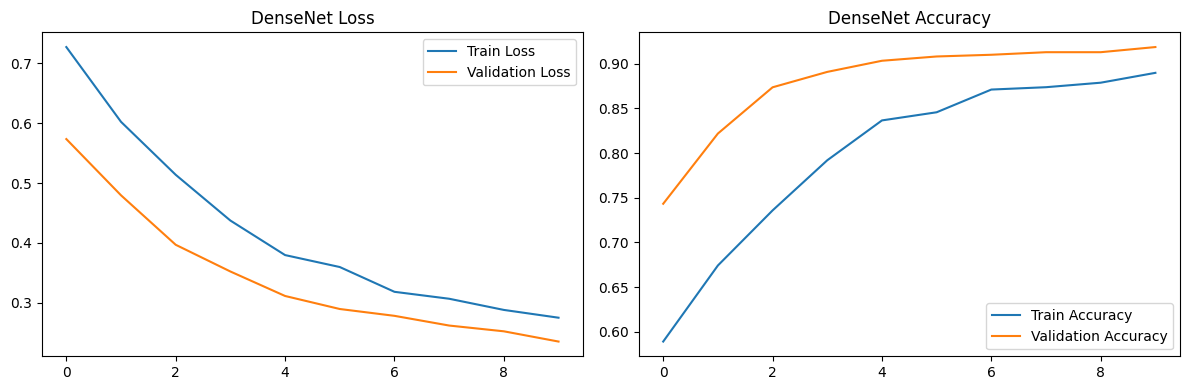

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_densenet.history["loss"], label="Train Loss")
plt.plot(history_densenet.history["val_loss"], label="Validation Loss")
plt.title("DenseNet Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_densenet.history["accuracy"], label="Train Accuracy")
plt.plot(history_densenet.history["val_accuracy"], label="Validation Accuracy")
plt.title("DenseNet Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
cnn_probs = cnn.predict(test_ds, verbose=0).reshape(-1)
dense_probs = densenet_model.predict(test_ds_dense, verbose=0).reshape(-1)
resnet_probs = resnet_model.predict(test_ds_resnet, verbose=0).reshape(-1)


In [ ]:
y_test = np.concatenate([
    labels.numpy().reshape(-1)
    for _, labels in test_ds
]).astype(int)

In [ ]:


import pandas as pd

from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score,
    roc_auc_score, confusion_matrix
)

def evaluate_model(name, probabilities, threshold=0.5):
    predictions = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1": f1_score(y_test, predictions),
        "AUC": roc_auc_score(y_test, probabilities),
        "Specificity": tn / (tn + fp),
        "False Negatives": fn,
        "False Positives": fp
    }

comparison_df = pd.DataFrame([
    evaluate_model("CNN (0.50)", cnn_probs),
    evaluate_model("CNN (val-tuned)", cnn_probs, CNN_THR),
    evaluate_model("DenseNet121", dense_probs, DENSE_THR),
    evaluate_model("ResNet50", resnet_probs, RESNET_THR)
])

display(comparison_df.round(4))

,Model,Accuracy,Precision,Recall,F1,AUC,Specificity,False Negatives,False Positives
0,CNN (0.50),0.6538,0.6460,0.9872,0.7809,0.8856,0.0983,5,211
1,CNN (val-tuned),0.7965,0.7816,0.9359,0.8518,0.8856,0.5641,25,102
2,DenseNet121,0.8798,0.8621,0.9615,0.9091,0.9568,0.7436,15,60
3,ResNet50,0.8494,0.8176,0.9769,0.8902,0.9628,0.6368,9,85


In [ ]:

def _snake(s):
    return s.lower().replace(" ", "_")

def log_test_metrics(run_id, row, threshold, suffix=""):
    with mlflow.start_run(run_id=run_id):
        mlflow.log_param(f"threshold{suffix}", threshold)
        mlflow.log_metrics({
            f"test_{_snake(k)}{suffix}": float(v)
            for k, v in row.items() if k != "Model"
        })

rows = comparison_df.set_index("Model")

log_test_metrics(cnn_run_id,    rows.loc["CNN (0.50)"],  0.5,      "_thr050")
log_test_metrics(cnn_run_id,    rows.loc["CNN (val-tuned)"],  CNN_THR,  "_tuned")
log_test_metrics(dense_run_id,  rows.loc["DenseNet121"], DENSE_THR)
log_test_metrics(resnet_run_id, rows.loc["ResNet50"],    RESNET_THR)

print("Test metrics logged to MLflow.")

Test metrics logged to MLflow.


In [ ]:
print([name for name in globals() if "dense" in name.lower()])

['Dense', 'prepare_for_densenet', 'train_ds_dense', 'val_ds_dense', 'test_ds_dense', 'densenet_model', 'history_densenet', 'dense_run_id', 'y_val_true_dense', 'y_val_prob_dense', 'DENSE_THR', 'dense_probs']


In [ ]:
import tensorflow as tf

THRESHOLD = DENSE_THR


inputs = tf.keras.Input(shape=(224, 224, 3))
outputs = densenet_model(inputs)


if outputs.shape[-1] == 2:
    pneumonia_prob = outputs[:, 1:2]
else:
    pneumonia_prob = outputs


@tf.keras.utils.register_keras_serializable()
class FixedThreshold(tf.keras.layers.Layer):
    def __init__(self, threshold=0.37, **kwargs):
        super().__init__(**kwargs)
        self.threshold = threshold

    def call(self, inputs):
        return tf.cast(inputs >= self.threshold, tf.float32)

    def get_config(self):
        config = super().get_config()
        config["threshold"] = self.threshold
        return config

prediction = FixedThreshold(
    threshold=THRESHOLD,
    name="fixed_threshold"
)(pneumonia_prob)

export_densenet = tf.keras.Model(
    inputs=inputs,
    outputs={
        "pneumonia_probability": pneumonia_prob,
        "prediction": prediction
    }
)

export_path = f"/content/densenet121_threshold_{int(round(THRESHOLD * 100)):03d}.keras"
export_densenet.save(export_path)

print("Saved:", export_path)

Saved: /content/densenet121_threshold_046.keras


In [ ]:

with mlflow.start_run(run_name="densenet121_final_export") as run:
    mlflow.set_tags({"stage": "final", "model_family": "densenet121"})
    mlflow.log_params({
        "threshold": THRESHOLD,
        "source_run_id": dense_run_id,
        "expected_input": "224x224x3, pixels*255 then densenet.preprocess_input",
    })

    dense_row = comparison_df.set_index("Model").loc["DenseNet121"]
    mlflow.log_metrics({f"test_{_snake(k)}": float(v) for k, v in dense_row.items() if k != "Model"})

    mlflow.log_artifact(export_path, artifact_path="final_model")

    comparison_df.to_csv("model_comparison.csv", index=False)
    mlflow.log_artifact("model_comparison.csv", artifact_path="reports")

    final_run_id = run.info.run_id

print("Final run id:", final_run_id)

Final run id: 54962ce144c242ccb08f159c72df15a8


### Download the latest final model from MLflow

In [ ]:
import os
import tensorflow as tf
from google.colab import files


runs = mlflow.search_runs(
    experiment_names=[EXPERIMENT],
    filter_string="tags.stage = 'final'",
    order_by=["attributes.start_time DESC"],
    max_results=1
)
assert len(runs) > 0, "No final run found - run the final logging cell first."
latest_run_id = runs.loc[0, "run_id"]
print("Latest final run:", latest_run_id)

run_info = mlflow.get_run(latest_run_id)
print("Threshold:", run_info.data.params["threshold"], "| Started:", run_info.info.start_time)
print({k: round(v, 4) for k, v in run_info.data.metrics.items() if k.startswith("test_")})


local_path = mlflow.artifacts.download_artifacts(
    run_id=latest_run_id,
    artifact_path="final_model/" + os.path.basename(export_path),
    dst_path="/content/downloaded_model"
)
print("Downloaded to:", local_path)


loaded = tf.keras.models.load_model(
    local_path,
    custom_objects={"FixedThreshold": FixedThreshold},
    compile=False
)
images, _ = next(iter(test_ds_dense))
out = loaded.predict(images, verbose=0)
print({k: v.shape for k, v in out.items()})


files.download(local_path)

Latest final run: 54962ce144c242ccb08f159c72df15a8
Threshold: 0.46439671516418457 | Started: 1793155392281
{'test_accuracy': 0.8798, 'test_precision': 0.8621, 'test_recall': 0.9615, 'test_f1': 0.9091, 'test_auc': 0.9568, 'test_specificity': 0.7436, 'test_false_negatives': 15.0, 'test_false_positives': 60.0}


Downloaded to: /content/downloaded_model/densenet121_threshold_046.keras
{'pneumonia_probability': (32, 1), 'prediction': (32, 1)}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>